# Homework 6
Viraj Dua  
GitHub: VirajD24  
DSCI 552: Machine Learning

note: the csv was too large when uploading so ill zip the data files;

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display         # to display tables in outputs
from sklearn.ensemble import RandomForestClassifier         # random forest classification model
from sklearn.impute import SimpleImputer            # filling missing values; i use each feature's median
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, roc_curve  # for conf matrix, auc, roc
from sklearn.model_selection import GridSearchCV, StratifiedKFold   # grid search: param comparison using cross-val; stratified: maintain class proportions across folds
from sklearn.pipeline import Pipeline       # preprocessing and model connect into one workflow
from sklearn.preprocessing import StandardScaler    # to center each feature, and scale it to unit sd
from imblearn.over_sampling import SMOTE    # for creating synthetic minority class examples to balance training data

from imblearn.pipeline import Pipeline as SamplingPipeline
# a pipline that also supports resampling steps like SMOTE
# I'm renaming it so it doesn't conflict with sklearn's pipeline ^^

from xgboost import XGBClassifier   # XGBoost classification model

plt.style.use("default")    # resetting plot style settings
sns.set_theme(style = "whitegrid", context = "notebook")    # white background; notebook text size
pd.set_option("display.precision", 4)   # decimal upto 4th
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None) # show every row and column

DATA_DIR = Path(".")        # looks for data files in notebook's working directory
SEED = 42   # consistent choices


## 1. Tree-Based Methods
### (a) Load the APS data

I loaded the given training and test sets without changing their split. I opened both csv and saw that the first 20 lines are the copyright info so i'll skip them. I'll convert the class labels to 0 for negative cases and 1 for positive cases.


In [2]:
train = pd.read_csv(DATA_DIR / "aps_failure_training_set.csv", skiprows = 20, na_values = "na")
test = pd.read_csv(DATA_DIR / "aps_failure_test_set.csv", skiprows = 20, na_values = "na")      # last attribute is to treat "na" as missing values

X_train = train.drop(columns = "class")     # intuition: create training data without the answers; the answer is under column "class" which im dropping
X_test = test.drop(columns = "class")       # intuition: this is testing data without answers, same logic.

# now let's convert the answers ("neg"/"pos") to 0 and 1
y_train = train["class"].eq("pos").astype(int)
y_test = test["class"].eq("pos").astype(int)
# train ["class"] selects the answers, .eq() is pandas is-equal-to "pos"?; if true => 1, if false => 0

display(pd.DataFrame({
    "Rows": [len(train), len(test)],    # len gives # of observations
    "Features": [X_train.shape[1], X_test.shape[1]],    # .shape[1] gives #of columns/features
        "Missing entries": [X_train.isna().sum().sum(), X_test.isna().sum().sum()]
}, index = ["Training", "Test"]))

# isna() marks missing cells as True; the first .sum() counts missing cells in each column, and the second .sum() adds those counts across all columns.
# my intuition: after loading data, displaying its size and showing how many values are missing;

,Rows,Features,Missing entries
Training,60000,170,850015
Test,16000,170,228680


### (b) Data preparation
#### i. Missing values

Missing values can be filled using the mean, median, similar observations, or predictions from other features. I use the median because it is simple and less affected by extreme values. No rows or features are removed.

I calculate each feature’s median from training data only and use it to fill missing values in both sets. During cross-validation, medians are recalculated using only that fold’s training portion. Unlike the approach suggested in the footnote, test data does not influence these values.

References: [imputation methods](https://scikit-learn.org/stable/modules/impute.html)
and [avoiding preprocessing leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).


#### ii. Coefficients of variation

I impute the training features and calculate `CV = sample standard deviation / mean` using `ddof=1`. i calculate CVs  for all 170 features and display the 13 largest


In [3]:
descriptive_imputer = SimpleImputer(strategy = "median")  # creating the tool to impute

# applying the tool to the features
X_descriptive = pd.DataFrame(
    descriptive_imputer.fit_transform(X_train), columns = X_train.columns
)
# fit_transform does 2 things: calculate each feature's median, fill its missing entries with that median
# and i convert the resulting array into to a table (pd.DataFrame)

# calculate each feature's coefficient of variation
variation = (
    X_descriptive.std(ddof=1) / X_descriptive.mean() # for each, sd/mean and store in CV
).rename("CV")

# display(variation.to_frame())     i tried this but the output was very long
display (variation.nlargest(13).to_frame())

,CV
cf_000,244.8875
co_000,244.5074
ad_000,244.3228
cs_009,237.9306
dh_000,123.2161
dj_000,117.4942
ag_000,92.9178
as_000,87.3325
ay_009,84.7337
ak_000,80.4250


#### iii. Correlation matrix

Correlations between all 170 features; strongly correlated groups implies overlapping information.


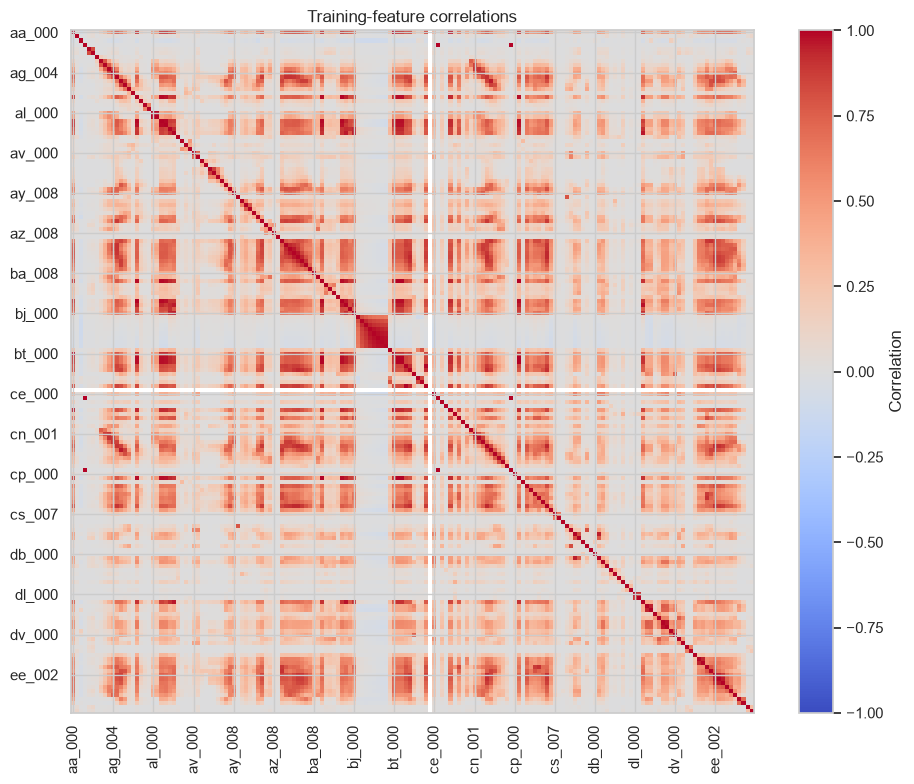

In [4]:
fig, ax = plt.subplots(figsize = (10, 8))   # 10 x 8 figure
image = ax.imshow(X_descriptive.corr(), cmap = "coolwarm", vmin = -1, vmax = 1)     # -1 to 1 covers all possible correlations

ticks = np.arange(0, X_train.shape[1], 10)      # create labeling slots every 10th feature to prevent overcrowding
ax.set_xticks(ticks, X_train.columns[ticks], rotation = 90)     # labeling those slots with feature names on axes; vertical rotation to fit
ax.set_yticks(ticks, X_train.columns[ticks])
fig.colorbar(image, ax = ax, label = "Correlation")      # color key
ax.set_title("Training-feature correlations")
plt.tight_layout()
plt.show()


#### iv. Highest-CV features

I plot the 13 features with the highest CV and compare their values across the two classes. I use log(1 + value) to make the large differences in scale easier to see. This transformation is only for the plots.


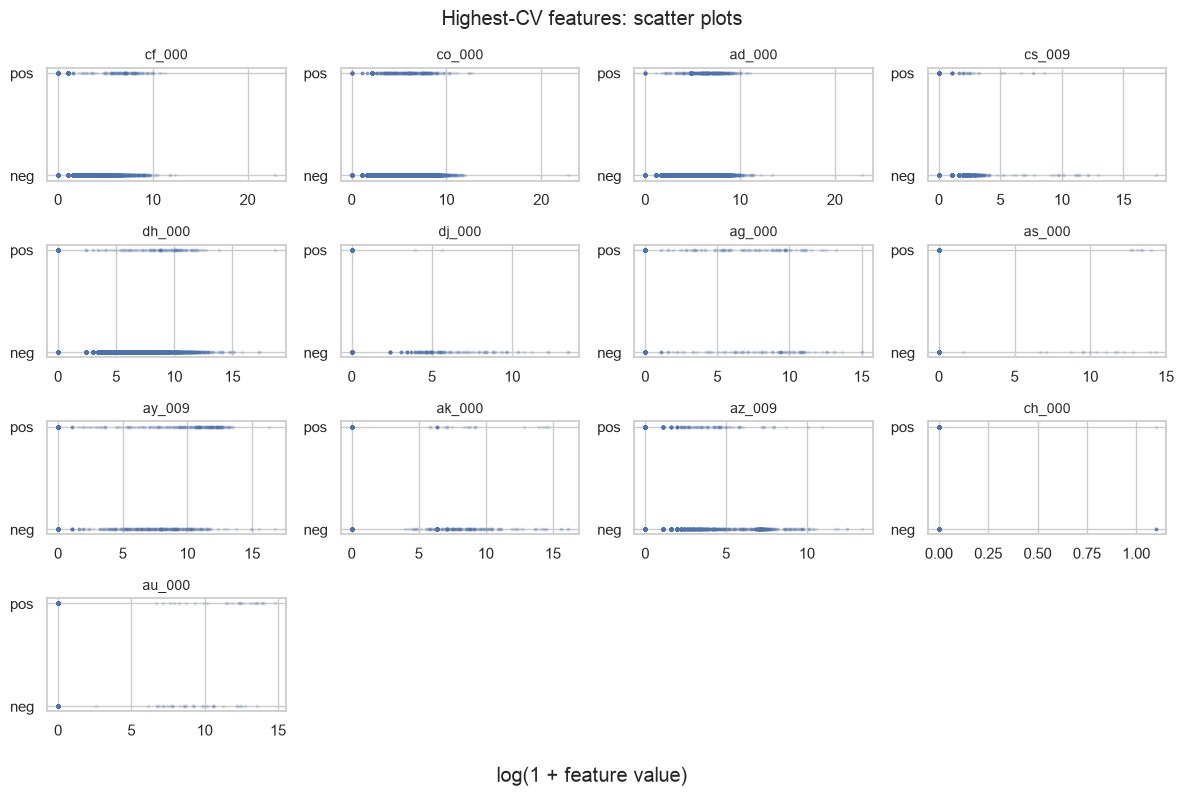

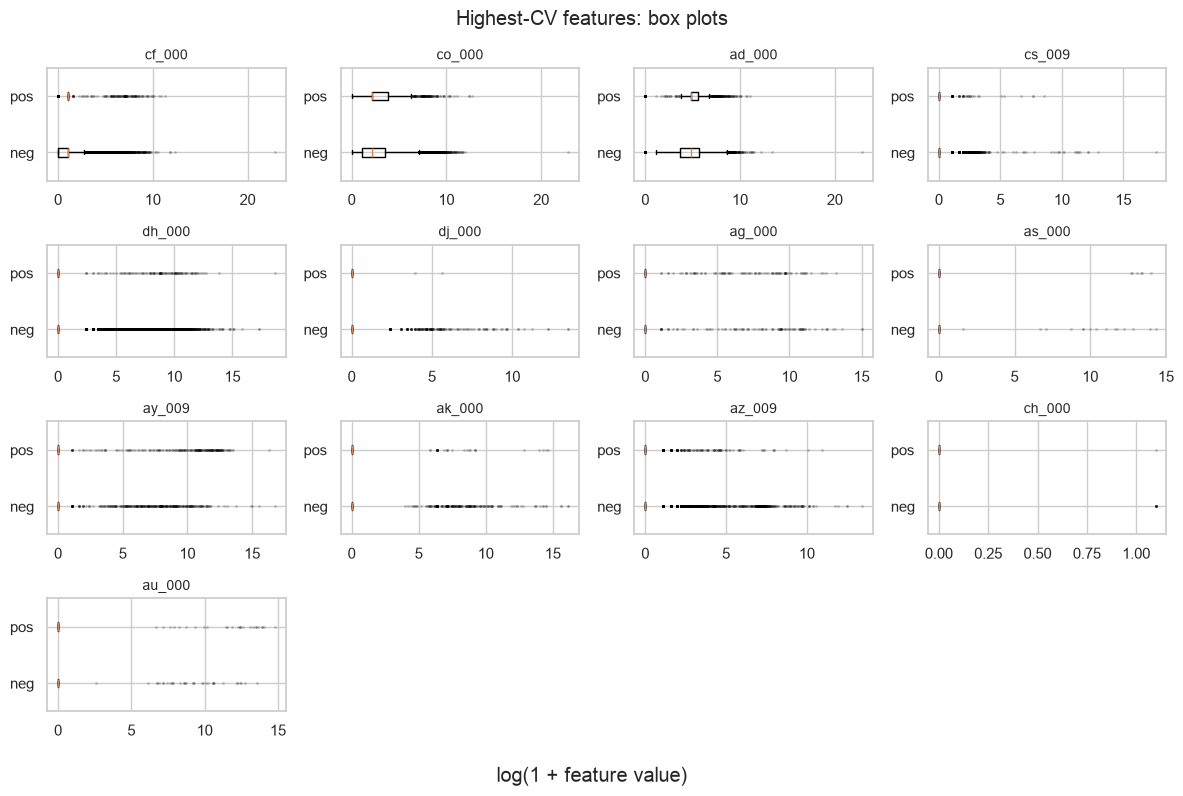

In [5]:
top_features = variation.nlargest(13).index
# uncomment this line under to display the 13; i commented it out to make the file normal sized; this is basically the same as 2 ii above; i displayed the 13 above;
# display(variation.loc[top_features].to_frame())


for plot_type in ["scatter", "box"]:
    fig, axes = plt.subplots(4, 4, figsize = (12, 8))   # 4x4 = 16; so im creating area for 16 plots; 16-13 =3 so 3 empty slots
    for ax, feature in zip(axes.flat, top_features):    # pairing each feature with one plotting area;
        values = np.log1p(X_descriptive[feature])   # log(1+value)
        if plot_type == "scatter":
            ax.scatter(values, y_train, s = 3, alpha = 0.12)       # size and transparency of the dots
            ax.set_yticks([0, 1], ["neg", "pos"])
        else:
            ax.boxplot([values[y_train == 0], values[y_train == 1]],
                       orientation="horizontal", tick_labels=["neg", "pos"],
                       flierprops={"markersize": 1, "alpha": 0.2})
            # im making 2 horizontal boxplots: one with negative cases, one with positive cases

        ax.set_title(feature, fontsize = 10) # labels
    for ax in axes.flat[len(top_features):]:
        ax.set_visible(False)       # this is to hide the 3 unused areas; we only needed 13
    fig.suptitle(f"Highest-CV features: {plot_type} plots")
    fig.supxlabel("log(1 + feature value)")
    plt.tight_layout()
    plt.show()


The distributions contain many zeros and a few extreme values. Some features
have different distributions across classes, but there is substantial overlap.
These plots alone do not establish statistical significance or a feature's
usefulness after accounting for other predictors. All 170 features are retained
for classification.

#### v. Class imbalance


In [6]:
class_counts = pd.DataFrame({
    "Training": y_train.value_counts(), "Test": y_test.value_counts()
}).rename(index={0: "Negative", 1: "Positive"})

display(class_counts)
print(f"Training negative-to-positive ratio: {class_counts.loc['Negative', 'Training'] / class_counts.loc['Positive', 'Training']:.0f}:1")
print(f"Always predicting negative gives training error {y_train.mean():.4f}.")

,Training,Test
class,,
Negative,59000,15625
Positive,1000,375


Training negative-to-positive ratio: 59:1
Always predicting negative gives training error 0.0167.


The training set is strongly imbalanced (59:1). A low overall error can therefore hide missed APS failures, so I also compare positive-class recall.

### (c) Random forest without imbalance compensation

I train a random forest with 300 trees and no class weighting or resampling. Missing values are filled using training-set medians.

I report training and test confusion matrices, ROC curves, AUC, and misclassification error. Recall is included to show how many positive cases are detected. Predictions use a threshold of 0.5.

OOB error uses trees that did not train on each observation. It evaluates the forest after imputation; the medians are not recalculated separately for each bootstrap sample.

Reference: [out-of-bag evaluation](https://scikit-learn.org/stable/auto_examples/ensemble/plot_ensemble_oob.html).

The linked source explains the exact OOB idea I used here: evaluate each observation using trees whose bootstrap samples excluded it. It also calculates OOB error as: 1 - model.oob_score_

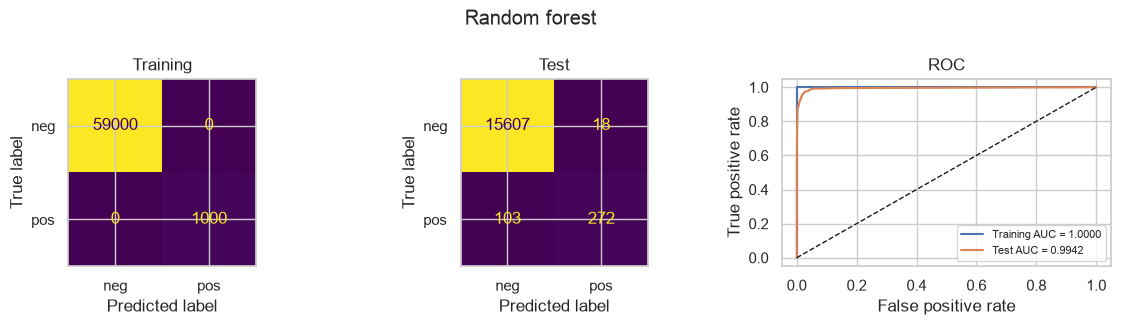

,Error,AUC,Recall,FP,FN
Split,,,,,
Training,0.0000,1.0000,1.0000,0,0
Test,0.0076,0.9942,0.7253,18,103


OOB error: 0.0058


In [7]:
results = []

def evaluate(model, name):
    rows = []
    fig, axes = plt.subplots(1, 3, figsize = (12, 3.3))
    for ax, split, X, y in zip(axes[:2], ["Training", "Test"], [X_train, X_test], [y_train, y_test]):
        probability = model.predict_proba(X)[:, 1]
        prediction = (probability >= 0.5).astype(int)
        cm = confusion_matrix(y, prediction, labels = [0, 1])
        tn, fp, fn, tp = cm.ravel()
        rows.append({"Model": name, "Split": split, "Error": (fp + fn) / len(y),
                     "AUC": roc_auc_score(y, probability), "Recall": tp / (tp + fn),
                     "FP": fp, "FN": fn})
        ConfusionMatrixDisplay(cm, display_labels = ["neg", "pos"]).plot( ax = ax, colorbar = False, values_format = "d")
        ax.set_title(split)
        fpr, tpr, _ = roc_curve(y, probability)
        axes[2].plot(fpr, tpr, label = f"{split} AUC = {rows[-1]['AUC']:.4f}")
    axes[2].plot([0, 1], [0, 1], "k--", linewidth=1)
    axes[2].set(xlabel = "False positive rate", ylabel = "True positive rate", title = "ROC")
    axes[2].legend(fontsize = 8)
    fig.suptitle(name)
    plt.tight_layout()
    plt.show()
    results.extend(rows)
    display(pd.DataFrame(rows).drop(columns="Model").set_index("Split"))

rf = Pipeline([
    ("imputer", SimpleImputer(strategy = "median")), ("model", RandomForestClassifier(n_estimators = 300, oob_score = True, random_state = SEED, n_jobs = 4))
])
rf.fit(X_train, y_train)
evaluate(rf, "Random forest")
print(f"OOB error: {1 - rf.named_steps['model'].oob_score_:.4f}")


The OOB error is 0.0058 versus a test error of 0.0076. OOB gives a slightly lower estimate in this split. Although training error is zero, the forest misses 103 of the 375 positive test cases.

### (d) Random forest with imbalance compensation
Common approaches include class weighting, minority oversampling, and majority undersampling. I use class_weight="balanced_subsample", which computes inverse-frequency class weights separately within each tree's bootstrap sample. This gives the two classes equal total weight within each tree. Other forest settings stay the same.

Reference: [random-forest class weights](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html#sklearn.ensemble.RandomForestClassifier).


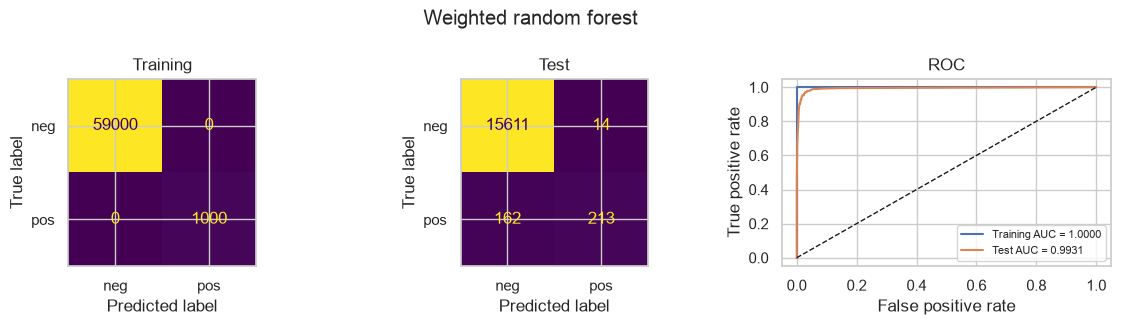

,Error,AUC,Recall,FP,FN
Split,,,,,
Training,0.000,1.0000,1.000,0,0
Test,0.011,0.9931,0.568,14,162


OOB error: 0.0076


In [8]:
rf_weighted = Pipeline([
    ("imputer", SimpleImputer(strategy = "median")),
    ("model", RandomForestClassifier(n_estimators = 300, oob_score = True, class_weight = "balanced_subsample", random_state = SEED, n_jobs = 4)) ])
rf_weighted.fit(X_train, y_train)
evaluate(rf_weighted, "Weighted random forest")
print(f"OOB error: {1 - rf_weighted.named_steps['model'].oob_score_:.4f}")


Weighting increases test error from 0.0076 to 0.011 and lowers positive recall from 0.7253 to 0.568. It reduces false positives slightly but misses more failures. The weighted forest's OOB error (0.0076) is again below its test error (0.0110). Class weighting does not improve this particular fit at the fixed threshold.

### (e) L1-regularized XGBoost without imbalance compensation

I use XGBoost and select alpha using five-fold stratified cross-validation. The reference explains the parameters; the search range and fixed settings are my implementation choices.

I chose [0, 0.01, 0.1, 1, 10, 100] to compare no L1 penalty with increasingly strong penalties. I select the alpha with the lowest average validation misclassification error. Both XGBoost models use 300 trees, maximum depth 4, and learning rate 0.05, kept fixed while tuning alpha. No class weighting or resampling is used here.

From the documentation, I understand that reg_alpha penalizes leaf scores, whereas the assignment describes L1-penalized logistic regression at each node. Since XGBoost is permitted, I use its documented L1 regularization, noting this difference.

Imputation and scaling are fitted within each training fold. Scaling is included in both models because SMOTE in part (f) uses distances. The test set is reserved for evaluation; the selected CV error may be optimistic because it also guides alpha selection.

Reference: [XGBoost parameter definitions](https://xgboost.readthedocs.io/en/stable/parameter.html).

,alpha,CV error
0,0.00,0.0057
1,0.01,0.0057
2,0.10,0.0056
3,1.00,0.0058
4,10.00,0.0064
5,100.00,0.0111


Selected alpha: 0.1
Selected five-fold CV error: 0.0056


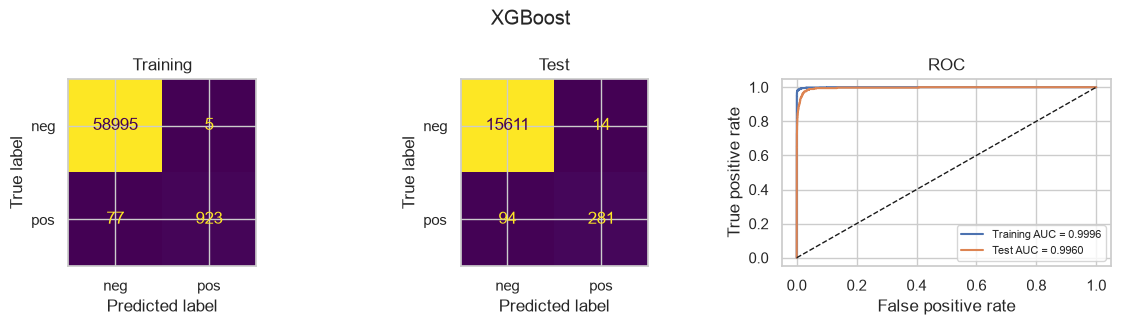

,Error,AUC,Recall,FP,FN
Split,,,,,
Training,0.0014,0.9996,0.9230,5,77
Test,0.0067,0.9960,0.7493,14,94


In [9]:
folds = StratifiedKFold(n_splits = 5, shuffle = True, random_state = SEED) # training data division into 5 groups; shuffle mixes before dividing;
alpha_grid = {"model__reg_alpha": [0, 0.01, 0.1, 1, 10, 100]}       # reg_alpha controls XGboost's l1 penalty on leaf weights

def tune_xgb(use_smote = False):      # tuning xg boost
    steps = [("imputer", SimpleImputer(strategy = "median")), ("scaler", StandardScaler())]
    # an ordered list of steps: 1. fill missing values, 2. center amd scale each feature

    if use_smote:
        steps.append(("smote", SMOTE(random_state=SEED))) # add smote only when requested

    steps.append(("model", XGBClassifier(
        objective = "binary:logistic", eval_metric = "logloss", n_estimators = 300,
        max_depth = 4, learning_rate = 0.05, reg_lambda = 0, tree_method = "hist",
        random_state = SEED, n_jobs = 4 )))
    # intuition behind these choices: binary classification, building 300 trees, limit each tree's depth to 4, each new tree's contribution small (learning_rate)
    # reg_lambda =0 means disabling L2 penalty so that we can investigate L1, histogram based splitting for speed, allow 4 processing threads
    # these settings stay fixed, only alpha is tuned

    # lets run the search
    search = GridSearchCV(SamplingPipeline(steps), alpha_grid, cv = folds, scoring = "accuracy", n_jobs = 1, error_score = "raise")
    search.fit(X_train, y_train)        # 6 alpha vals * 5 folds = 30 fits

    #results
    display(pd.DataFrame({
        "alpha": search.cv_results_["param_model__reg_alpha"],
        "CV error": 1 - search.cv_results_["mean_test_score"]     }))
    print(f"Selected alpha: {search.best_params_['model__reg_alpha']}")
    print(f"Selected five-fold CV error: {1 - search.best_score_:.4f}")
    return search

xgb = tune_xgb()
evaluate(xgb.best_estimator_, "XGBoost")


CV selects alpha = 0.1, with error 0.0056 compared with test error 0.0067. The test AUC is 0.9960, but the 0.5 threshold still misses 94 positive cases.

### (f) XGBoost with SMOTE

I use SMOTE to balance the training data, as asked. Following the [SMOTE explanation](https://imbalanced-learn.org/stable/over_sampling.html#sample-generation), synthetic positive observations are generated between nearby positive observations. The final training fit contains 59,000 observations per class, or 118,000 total.

and following [pipeline guidance](https://imbalanced-learn.org/stable/common_pitfalls.html#data-leakage), each fold applies imputation, scaling, and SMOTE using only its training portion, then fits XGBoost. Validation and test data are never oversampled. Applying SMOTE before dividing the folds could leak information into training.

I reuse part (e)’s settings and alpha search. Training performance is evaluated on the original 60,000 observations.

,alpha,CV error
0,0.00,0.0122
1,0.01,0.0123
2,0.10,0.0121
3,1.00,0.0122
4,10.00,0.0130
5,100.00,0.0205


Selected alpha: 0.1
Selected five-fold CV error: 0.0121


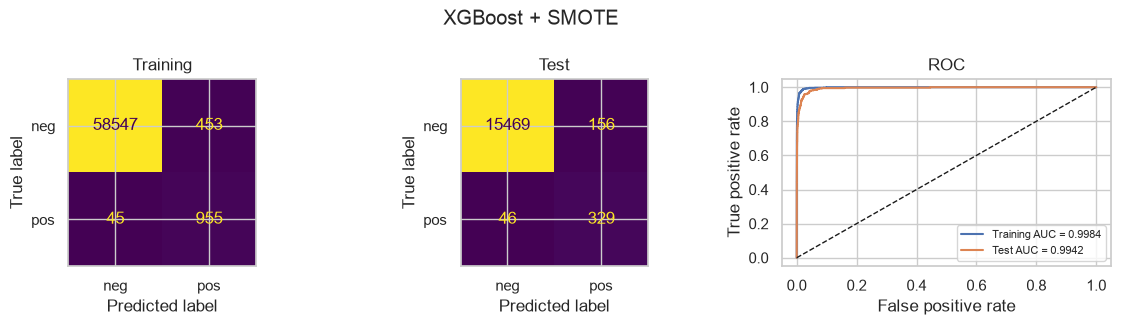

,Error,AUC,Recall,FP,FN
Split,,,,,
Training,0.0083,0.9984,0.9550,453,45
Test,0.0126,0.9942,0.8773,156,46


,Error,AUC,Recall,FP,FN
Model,,,,,
Random forest,0.0076,0.9942,0.7253,18,103
Weighted random forest,0.0110,0.9931,0.5680,14,162
XGBoost,0.0067,0.9960,0.7493,14,94
XGBoost + SMOTE,0.0126,0.9942,0.8773,156,46


In [10]:
xgb_smote = tune_xgb(use_smote = True)  # running the same search with smote enabled
evaluate(xgb_smote.best_estimator_, "XGBoost + SMOTE")      # evaluates the selected model using the original training and test sets
summary = pd.DataFrame(results).query("Split == 'Test'").drop(columns="Split").set_index("Model")
display(summary)

SMOTE also selects alpha = 0.1. Its CV error is 0.0121, close to its test error of 0.0126. Relative to XGBoost without SMOTE, positive recall rises from 0.7493 to 0.8773 and false negatives fall from 94 to 46, but false positives rise from 14 to 156. Overall error increases and AUC falls slightly. SMOTE improves failure detection at this threshold, not every measure of performance.


## 2. ISLR 6.6.3: Increasing the LASSO constraint

Increasing `s` in the constraint $\sum_j |\beta_j| \leq s$ allows larger coefficients and a more flexible fit.

| Part | Choice | Explanation |
|---|---|---|
| (a) Training RSS | **iv. Decreases** | The feasible set expands, so its minimum RSS cannot increase; it can level off once least squares is feasible. |
| (b) Test RSS | **ii. U-shaped** | Typically decreases as underfitting falls, then increases as variance and overfitting grow. |
| (c) Variance | **iii. Increases** | Less shrinkage makes the fitted model more sensitive to the training sample. |
| (d) Squared bias | **iv. Decreases** | Less shrinkage permits a closer approximation to the underlying relationship. |
| (e) Irreducible error | **v. Constant** | Changing the fitting constraint does not change the noise in the response. |

The test-error, bias, and variance descriptions are the usual bias-variance patterns, not guaranteed strictly monotone behavior in every dataset.


## 3. ISLR 6.6.5: Identical predictors

Let $x_i=x_{i1}=x_{i2}$ and $t=\beta_1+\beta_2$. The given centering makes the intercept zero. Assume $\lambda>0$.

**(a) Ridge objective:**

$$
\min_{\beta_1,\beta_2}\;\sum_{i=1}^{2}[y_i-x_i(\beta_1+\beta_2)]^2+\lambda(\beta_1^2+\beta_2^2).
$$

**(b)** For a fixed sum $t$, the RSS is unchanged, but

$$
\beta_1^2+\beta_2^2=\frac{t^2}{2}+\frac{(\beta_1-\beta_2)^2}{2}.
$$

The penalty is smallest when $\hat\beta_1=\hat\beta_2=t/2$.

**(c) LASSO objective:**

$$
\min_{\beta_1,\beta_2}\;\sum_{i=1}^{2}[y_i-x_i(\beta_1+\beta_2)]^2+\lambda(|\beta_1|+|\beta_2|).
$$

**(d)** For a fixed $t$, the smallest penalty is $\lambda|t|$, attained by any split with both coefficients having the same sign (or one being zero). If the optimal sum is $t^*\neq0$, all pairs

$$
(\hat\beta_1,\hat\beta_2)=(a t^*,(1-a)t^*),\qquad 0\leq a\leq1
$$

have identical fitted values and objectives, so the coefficients are not unique. Unlike ridge, LASSO need not divide the effect equally. If the penalty makes $t^*=0$, the solution is instead uniquely $(0,0)$ for $\lambda>0$.


## 4. ISLR 8.4.5: Combining bootstrap predictions

**Majority vote:** Six of the ten probabilities exceed 0.5, so six trees predict Red and four predict Green. The final classification is **Red**.

**Average probability:** The ten probabilities sum to 4.5, giving an average of 0.45. Since this is below 0.5, the final classification is **Green**.

## 5. ISLR 9.7.3: Maximal-margin classifier

**(a)-(e)** The plot below shows all seven observations, the optimal boundary,
its margins, and circled support vectors. The red support points have
$X_2-X_1=0$ and the blue support points have $X_2-X_1=-1$, so the halfway boundary is

$$
\tfrac12-X_1+X_2=0.
$$

Classify **Red** if $\tfrac12-X_1+X_2>0$, and **Blue** otherwise.
Thus $(\beta_0,\beta_1,\beta_2)=(\tfrac12,-1,1)$.
The margin lines are $X_2=X_1$ and $X_2=X_1-1$; the distance from the boundary
to either line is $1/(2\sqrt2)$. Support observations are **2, 3, 5, and 6**.

**(f)** Observation 7 is away from the margin. A sufficiently small movement
keeps it outside the margin and does not change the optimal boundary.

**(g)** $X_2=X_1-\tfrac14$ also separates the classes, but its minimum distance
to a training point is only $1/(4\sqrt2)$, so it is not optimal.

**(h)** Adding a Blue observation at $(3,3)$ prevents strict linear separation:
it lies on the line segment between Red observations 2 and 3. A linear score
positive at both endpoints must also be positive at their midpoint.


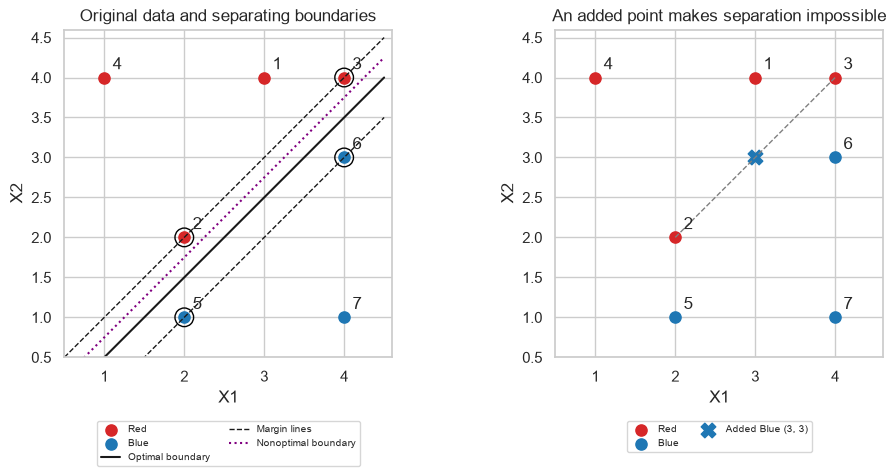

In [11]:
# the 7 observations given; first 4 are red
points = np.array([[3, 4], [2, 2], [4, 4], [1, 4], [2, 1], [4, 3], [4, 1]])
red = np.array([True, True, True, True, False, False, False])

# horizontal coordinates for drawing the straight lines
line = np.linspace(0.5, 4.5, 100)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.8))

# original observations in both panels
for ax in axes:
    ax.scatter(*points[red].T, c = "tab:red", label = "Red", s = 65)    # .T separates x1 and x2; * passes them to scatter
    ax.scatter(*points[~red].T, c = "tab:blue", label = "Blue", s = 65)

    # number the observations to match the exercise
    for number, (x1, x2) in enumerate(points, 1):
        ax.annotate(str(number), (x1, x2), xytext = (6, 6), textcoords = "offset points")
    ax.set(xlabel = "X1", ylabel = "X2", xlim = (0.5, 4.6), ylim = (0.5, 4.6))  # same physical scale on both axes
    ax.set_aspect("equal")

# Closest class edges lie on X2 = X1 and X2 = X1 - 1
# The optimal boundary is halfway between them: X2 = X1 - 0.5
axes[0].plot(line, line - 0.5, "k-", label = "Optimal boundary")
axes[0].plot(line, line, "k--", linewidth = 1, label = "Margin lines")
axes[0].plot(line, line - 1, "k--", linewidth = 1)

# This also separates the classes, but has a smaller minimum margin
axes[0].plot(line, line - 0.25, ":", color = "purple", label = "Nonoptimal boundary")

# circle around points 2, 3, 5, and 6
# My intuition: circle the points closest to the separating line. These are the support vectors: they limit how wide the margin can be.
axes[0].scatter(*points[[1, 2, 4, 5]].T, s = 180, facecolors = "none", edgecolors = "black")
axes[0].set_title("Original data and separating boundaries")
axes[1].plot([2, 4], [2, 4], "--", color = "gray", linewidth = 1)
axes[1].scatter(3, 3, marker = "X", c = "tab:blue", s = 110, label = "Added Blue (3, 3)")
axes[1].set_title("An added point makes separation impossible")
for ax in axes:
    ax.legend(fontsize= 7, loc = "upper center", bbox_to_anchor =(0.5, -0.18), ncol = 2)
plt.tight_layout()
plt.show()

Supporting references: the [maximum-margin illustration](https://scikit-learn.org/stable/auto_examples/svm/plot_separating_hyperplane.html) explains boundaries and support vectors, while the [point-to-line distance formula](https://mathworld.wolfram.com/2-DimensionalPoint-LineDistance.html) supports my margin calculation. The specific boundary and support observations are derived from the exercise’s seven points.